# New Narratives for old Buildings

---



Finding narratives through comparison of term frequency across countries

In [1]:
import os, re, csv
import pandas as pd
import numpy as np
import pickle
import matplotlib.pyplot as plt

## Loading the dataset: heritage homes webistes


In [ ]:
from google.colab import drive
drive.mount('/content/gdrive')

In [2]:
#path = '/content/gdrive/MyDrive/CDA/' # working with google drive and colab

path = 'datasets/' # working locally

In [3]:
# Country code: change here between 'NL' and 'UK'
cc_list = ['NL', 'UK', 'DE', 'FR']

In [4]:
# Import json data from Aipfy scraping into 4 separate dataframes
df_NL=pd.read_json(path+cc_list[0]+'_dataset_website-content-crawler.json') # NL
# select only two columns for analysis: url and text
df_NL=df_NL[['url','text']]

df_UK=pd.read_json(path+cc_list[1]+'_dataset_website-content-crawler.json') # UK
# select only two columns for analysis: url and text
df_UK=df_UK[['url','text']]

df_DE=pd.read_json(path+cc_list[2]+'_dataset_website-content-crawler.json') # DE
# select only two columns for analysis: url and text
df_DE=df_DE[['url','text']]

df_FR=pd.read_json(path+cc_list[3]+'_dataset_website-content-crawler.json') # FR
# select only two columns for analysis: url and text
df_FR=df_FR[['url','text']]

df_FR.head()

,url,text
0,https://www.chateau-combourg.com/privatisation,Events — COMBOURG\nLe château et le parc peuve...
1,https://www.chateau-combourg.com/chateaubriand,Chateaubriand — COMBOURG\nFrançois-René de Cha...
2,https://www.chateau-combourg.com/prixlitteraire,Prix Littéraire — COMBOURG\nLe Prix Combourg-C...
3,https://www.chateau-combourg.com/contact,Contact — COMBOURG\nNom(obligatoire)\nPrénom\n...
4,https://www.suscinio.fr/,Château de Suscinio dans le Morbihan\nOuvert t...


In [5]:
len(df_UK)

27464

Join all pages from a domain to an entry in the analysis. To do this, add a new column which will contain only the main domain name.

In [6]:
# function to extract the main domain from the url in the dataset (ALL DOMAINS)
def extract_main_domain(url):
    if not isinstance(str(url), str):
        print('NOT VALID',url)
        return None
    match = re.findall('(?:\w+\.)*[\w\-]+\.\w*', str(url)) #'www\.?([^/]+)'
    return match[0].lstrip('www.') if match else None

In [7]:
# Add a new column 'domain' and fill it by applying the extract_main_domain function to the 'url' column

# first, create a mapping of dataframes which could be addressed in a loop
df_dict = {'0':df_NL, '1':df_UK, '2':df_DE, '3':df_FR}

# then, loop through the df_dict to update each dataframe
for k, v in df_dict.items():
  cc_column = cc_list[int(k[-1])]+' domains'
  cc = cc_list[int(k[-1])]
  # print(cc_column, cc)
  urls = pd.read_csv('url_lists/'+cc_list[int(k[-1])]+'_urls.csv')[cc_column].values.tolist()
  domains = {extract_main_domain(url) for url in urls if extract_main_domain(url) is not None}
  matching_links = [link for link in v.url if extract_main_domain(link) in domains]
  # update the dataframe
  v['domain'] = v['url'].apply(extract_main_domain)

In [8]:
# check one of the dataframes
df_DE.head()

,url,text,domain
0,http://www.schlossparkmarisfeld.de/,Schlosspark Marisfeld - Schlosspark Marisfeld\...,schlossparkmarisfeld.de
1,http://www.schlossparkmarisfeld.de/information...,Informationen zur Geschichte des Schlossparks\...,schlossparkmarisfeld.de
2,http://www.schlossparkmarisfeld.de/information...,Der Schlosspark Marisfeld - Kleine Parkgeschic...,schlossparkmarisfeld.de
3,http://www.schlossparkmarisfeld.de/information...,Der Förderverein stellt sich vor\nDer aktuelle...,schlossparkmarisfeld.de
4,http://www.schlossparkmarisfeld.de/information...,Die Vereinssatzung - Schlosspark Marisfeld\nFa...,schlossparkmarisfeld.de


In [ ]:
# review the list of unique domains as they appear in the df
df_DE.domain.unique()

In [ ]:
# Combine all pages from one domain into a list of pages
# copy one url from the list of unique domains above
website = 'schloss-gutshof-britz.de'
document = df_DE[df_DE['domain'] == website]['text'].tolist() # df_DE should match with df_DE above, or change both

# remove new line characters, count words&characters in each line of the text
clean_document = []
word_count = 0
character_count = 0
for i in document:
    j = i.replace('\n', ' ').replace('\r', '')
    w = len(j.split())
    word_count += w
    character_count +=len(j)
    clean_document.append(j)

print('word_count:', word_count, '\ncharacter_count:', character_count)
clean_document

# Compare term frequencies across corpora

## Terms related to activities, culture, styles, nobility

In [9]:
# list terms to compare
activities = ['kind','spel','avontuur',
              'child','game','adventure',
              'kind', 'spiel', 'abenteuer',
              'enfant', 'jeu', 'aventure']
events = ['feest','bruiloft','bruid','bruidegom',
          'party','wedding','bride','groom',
          'party', 'hochzeit', 'braut', 'bräutigam',
          'fête', 'mariage', 'mariée', 'marié']
nobility = ['graaf','baron','hertog',
            'earl','baron','duke',
            'graf','baron','herzog',
            'compte','baron','duc']
culture = ['tentoonstelling','museum','tuin','park','collectie',
           'exhibition','museum','garden','park','collection',
           'ausstellung','museum','garten','park','sammlung',
           'exposition','musée','jardin','parc','collection']
styles = ['rococo', 'barok', 'renaissance', 'gotiek', # or gotisch
          'rococo', 'baroque', 'renaissance', 'gothic',
          'rokoko', 'barock', 'renaissance', 'gotik',
          'rococo', 'baroque', 'renaissance', 'gothique']

Create texts as 'documents' to count terms and perform tf-idf

In [10]:
# count term frequencies across four dataframes
list_to_count = events # replace with the name of a list of terms (above)
dataframes = [df_NL, df_UK, df_DE, df_FR] # list of dataframes
number_of_terms = int(len(list_to_count) / 4) # calculate the number of terms in 1 language

term_count_dict = {}
start, end = 0, number_of_terms
for i, df in enumerate(dataframes):
  term_count_values = []
  for term in list_to_count[start:end]:
    #print(term)
    term_count_column = sum([str(item).lower().count(term) for item in df['text'].tolist()])
    #print(int(term_count_column.sum()))
    term_count_values.append(int(term_count_column))
  start += number_of_terms
  end += number_of_terms
  term_count_dict[cc_list[i]] = term_count_values

term_count_dict

{'NL': [1409, 273, 337, 5],
 'UK': [1481, 3527, 306, 129],
 'DE': [268, 592, 66, 3],
 'FR': [1040, 694, 21, 71]}

In [12]:
list_to_count = events # replace with the name of a list of terms (above)       
list_name = 'events' # replace with the name of a list of terms as a 'string'         
dataframes = [df_NL, df_UK, df_DE, df_FR]
whole_word = True   # True: match whole words only; False: match any substring
number_of_terms = len(list_to_count) // 4 

for i, (cc, df) in enumerate(zip(cc_list, dataframes)):
    terms = list_to_count[i * number_of_terms:(i + 1) * number_of_terms]
    texts = df['text'].fillna('').astype(str).str.lower().tolist()
    urls = df['url'].tolist()

    rows = []
    for term in terms:
        t = re.escape(term.lower())
        pattern = re.compile(r'(?<!\w)' + t + r'(?!\w)' if whole_word else t)
        for url, text in zip(urls, texts):
            hits = len(pattern.findall(text))
            if hits:
                rows.append((term, url, hits))   # one row per term and page

    out = pd.DataFrame(rows, columns=['term', 'url', 'count'])
    out.to_csv(f'outputs/csv/{cc}_2024_{list_name}.csv', index=False)
    print(cc, len(out), 'rows saved')

NL 252 rows saved
UK 1599 rows saved
DE 281 rows saved
FR 568 rows saved


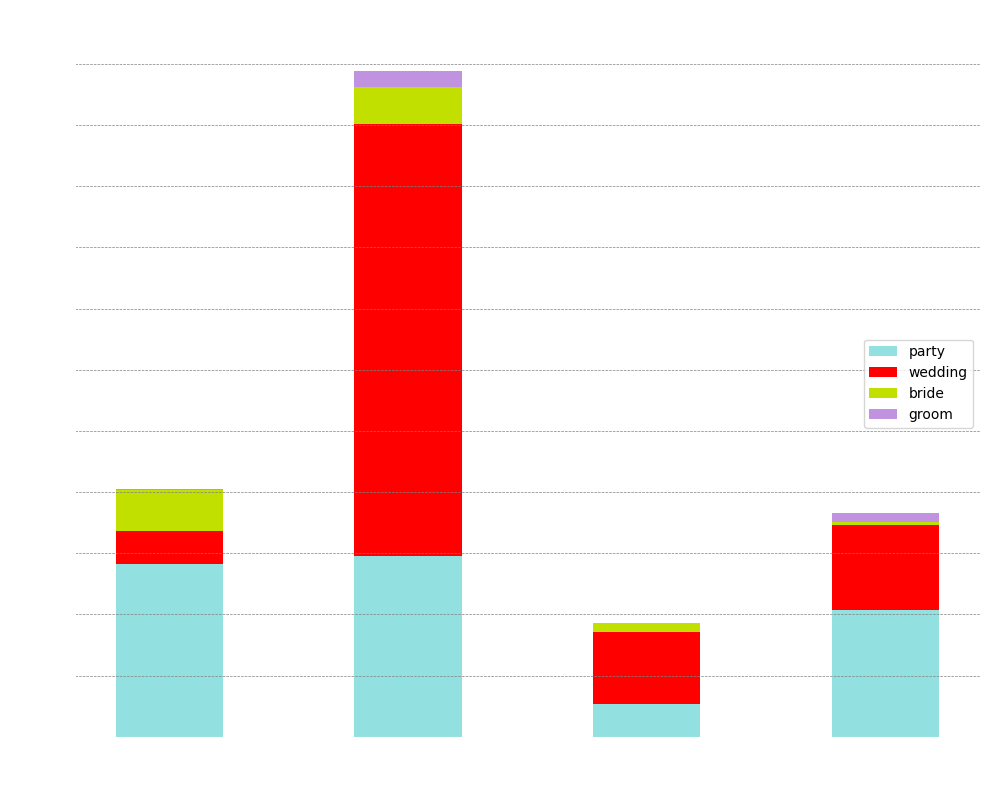

In [23]:
# Visualize the term count as a stacked bar chart per country
terms = list_to_count[number_of_terms:number_of_terms*2] # change which section of the list is used in the legend
# Create a list of countries (y-axis labels)
countries = list(term_count_dict.keys())

# Create the stacked bar chart
width = 0.45  # Width of the bars

fig, ax = plt.subplots(figsize=(10,8))

bottom = np.zeros(len(countries))
colors = ['#92E0E0', 'red', '#C1E000', '#C192E0','#E05543','#E0C200']

# Add horizontal lines for values in the legend
for value in [500, 1000, 1500, 2000, 2500, 3000, 3500, 4000, 4500, 5000, 5500]:
    #[100, 200, 300, 400, 500, 600, 700, 800, 900, 1000]:
    #[100, 500, 1000, 1500, 2000, 2500, 3000, 3500, 4000]:
    #[250, 500, 750, 1000, 1250, 1500, 1750, 2000, 2250, 2500, 2750]:
    #[500, 1000, 1500, 2000, 2500, 3000, 3500, 4000, 4500, 5000, 5500]: # events
    #[1000, 2000, 3000, 4000, 5000, 6000, 7000, 8000, 9000, 10000]:
    #[2000, 4000, 6000, 8000, 10000, 12000, 14000, 16000, 18000]: # activities
    #[2500, 5000, 7500, 10000, 12500, 15000, 17500, 20000, 22500, 25000, 27500] # arts & culture
    #[10000, 20000, 30000, 40000, 50000, 60000, 70000, 80000, 90000]:
  plt.axhline(y=value, color='grey', linestyle='--', linewidth=0.5)

for term_index in range(len(terms)):
    term_counts = [term_count_dict[country][term_index] for country in countries]
    ax.bar(countries, term_counts, width, label=terms[term_index], bottom=bottom,
           color=colors[term_index % len(colors)])
    bottom += np.array(term_counts)

ax.set_xlabel('Countries', color='white')
ax.set_ylabel('Term Counts', color='white')
ax.set_title('Terms related to '+list_name+' per country', color='white')
ax.spines['bottom'].set_color('white')
ax.spines['top'].set_color('white')
ax.spines['left'].set_color('white')
ax.spines['right'].set_color('white')
ax.tick_params(axis='x', colors='white')
ax.tick_params(axis='y', colors='white')
ax.legend()

plt.tight_layout()
plt.savefig('outputs/2024_'+list_name+'.png', transparent=True)
plt.show()

In [89]:
# count term frequencies across four dataframes
terms = ['architectuur', 'architecture', 'architektur', 'architecture'] # replace with the name of a list of terms (above)
dataframes = [df_NL, df_UK, df_DE, df_FR] # list of dataframes

term_count_dict = {}
for i, df in enumerate(dataframes):
  term_count_values = []
  #print(terms[i])
  term_count_column = sum([str(item).lower().count(terms[i]) for item in df['text'].tolist()])
  #print(int(term_count_column.sum()))
  term_count_values.append(int(term_count_column))
  term_count_dict[cc_list[i]] = term_count_values

term_count_dict

{'NL': [128], 'UK': [1528], 'DE': [556], 'FR': [3889]}

In [23]:
list_to_count = nobility # replace with the name of a list of terms activities / events / nobility / culture / styles
feature_names = [feature_names_NL, feature_names_UK, feature_names_DE, feature_names_FR] # list of dataframes
tfidf_scores = [tfidf_scores_NL, tfidf_scores_UK, tfidf_scores_DE, tfidf_scores_FR]
number_of_terms = int(len(list_to_count) / 4) # calculate the number of terms in 1 language

term_count_dict = {}
start, end = 0, number_of_terms
for i, fn in enumerate(feature_names):
  term_count_values = []
  for term in list_to_count[start:end]:
    #print(term)
    if term in fn:
      #print(term)
      term_index = list(fn).index(term)
      # Calculate the aggregated TF-IDF score for the term 'park'
      total_tfidf_score = tfidf_scores[i][:, term_index].sum()
      average_tfidf_score = tfidf_scores[i][:, term_index].mean()
    #print(int(term_count_column.sum()))
    term_count_values.append(float(average_tfidf_score))
  start += number_of_terms
  end += number_of_terms
  term_count_dict[cc_list[i]] = term_count_values

term_count_dict

{'NL': [0.0007159273352104525, 0.0019289694676604247, 0.0004029775218542135],
 'UK': [0.001334487525659943, 0.00034047550895950147, 0.001168679245947806],
 'DE': [0.0011460390914352476, 0.00011979592398027848, 0.0010664374280878847],
 'FR': [0.0011410641233413376, 0.0001949087993802904, 0.0027267206633930477]}

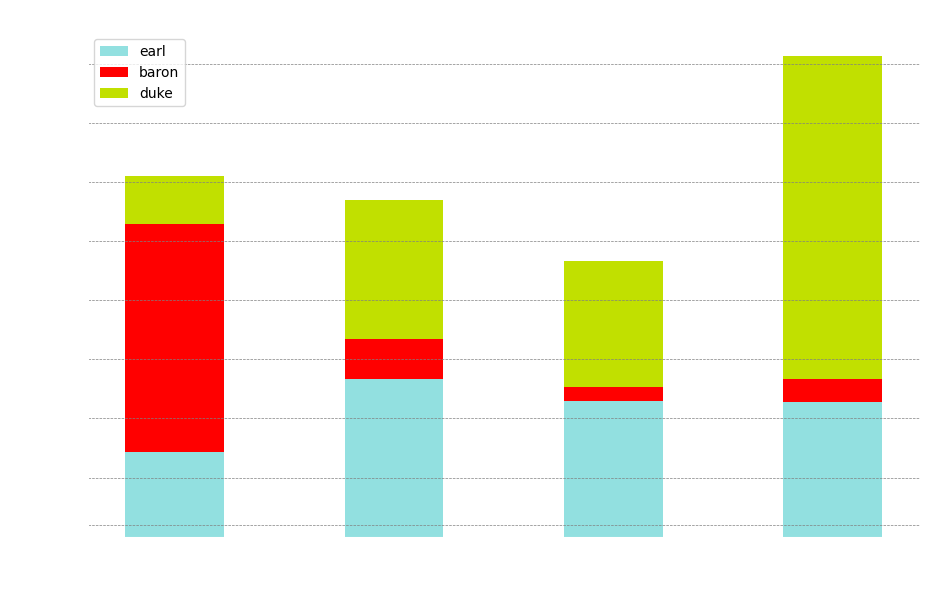

In [24]:
# Visualize the term count as a stacked bar chart per country
theme = list_to_count[number_of_terms+1]
terms = list_to_count[number_of_terms:number_of_terms*2] # change which section of the list is used in the legend
# Create a list of countries (y-axis labels)
countries = list(term_count_dict.keys())

# Create the stacked bar chart
width = 0.45  # Width of the bars

fig, ax = plt.subplots(figsize=(9.4,6))

bottom = np.zeros(len(countries))
colors = ['#92E0E0', 'red', '#C1E000', '#C192E0','#E05543','#E0C200']

# Add horizontal lines for values in the legend
for value in [0.0001, 0.0005, 0.001, 0.0015, 0.002, 0.0025, 0.003, 0.0035, 0.004]:
    #[0.0001, 0.0005, 0.001, 0.0015, 0.002, 0.0025, 0.003, 0.0035] # nobility
    #[0.002, 0.004, 0.006, 0.008, 0.01, 0.012, 0.014] # activities
    #[0.005, 0.01, 0.015, 0.02, 0.025, 0.03, 0.035, 0.04, 0.045] # culture
    #[0.001, 0.002, 0.003, 0.004, 0.005, 0.006, 0.007, 0.008, 0.009] # events + styles
  plt.axhline(y=value, color='grey', linestyle='--', linewidth=0.5)

for term_index in range(len(terms)):
    term_counts = [term_count_dict[country][term_index] for country in countries]
    ax.bar(countries, term_counts, width, label=terms[term_index], bottom=bottom,
           color=colors[term_index % len(colors)])
    bottom += np.array(term_counts)

ax.set_xlabel('Countries', color='white')
ax.set_ylabel('Term Counts', color='white')
ax.set_title('Terms related to '+theme+' per country', color='white')
ax.spines['bottom'].set_color('white')
ax.spines['top'].set_color('white')
ax.spines['left'].set_color('white')
ax.spines['right'].set_color('white')
ax.tick_params(axis='x', colors='white')
ax.tick_params(axis='y', colors='white')
ax.legend()

plt.tight_layout()
plt.savefig('outputs/2024_tfidf_'+theme+'.png', transparent=True)
plt.show()


## Terms related to social inequality 

In [34]:
# country list: 'NL', 'UK', 'DE', 'FR'
# dictionary of inequality terms:
inequality_terms = {
    'NL': ['koloni', 'slaven',
           'democratie', 'armoede',
           'bediende', 'arbeider'],
    'UK': ['coloni', 'slave', 'slavery',
           'inequality', 'democracy', 'poverty',
           'servant', 'worker', 'labourer'],
    'DE': ['koloni', 'sklave', 'sklaverei',
           'ungleichheit', 'demokratie', 'armut',
           'diener', 'arbeiter'],
    'FR': ['coloni', 'esclave', 'esclavage',
           'inégalité', 'démocratie', 'pauvreté',
           'serviteur', 'travailleur', 'ouvrier'],
}

In [42]:
# count all terms for all dfs
for cc, df in zip(cc_list, dataframes):
    terms = inequality_terms[cc]
    for term in terms:
        df[term] = df['text'].apply(lambda x: x.lower().count(term) if isinstance(x, str) else 0)

    # Filter for rows where 'kasteel' appears at least once
    mask = (df[terms] > 0).any(axis=1)

    # Filter the DataFrame based on the boolean mask.
    df_filtered = df[mask]

    # Create the five-column table
    filter_list = ['domain','url'] + terms
    result_df = df_filtered[filter_list]
    result_df.to_csv(f'outputs/csv/{cc}_2024_inequality.csv', index=False)
    print(cc, len(result_df), 'rows saved')

NL 117 rows saved
UK 1535 rows saved
DE 566 rows saved
FR 257 rows saved


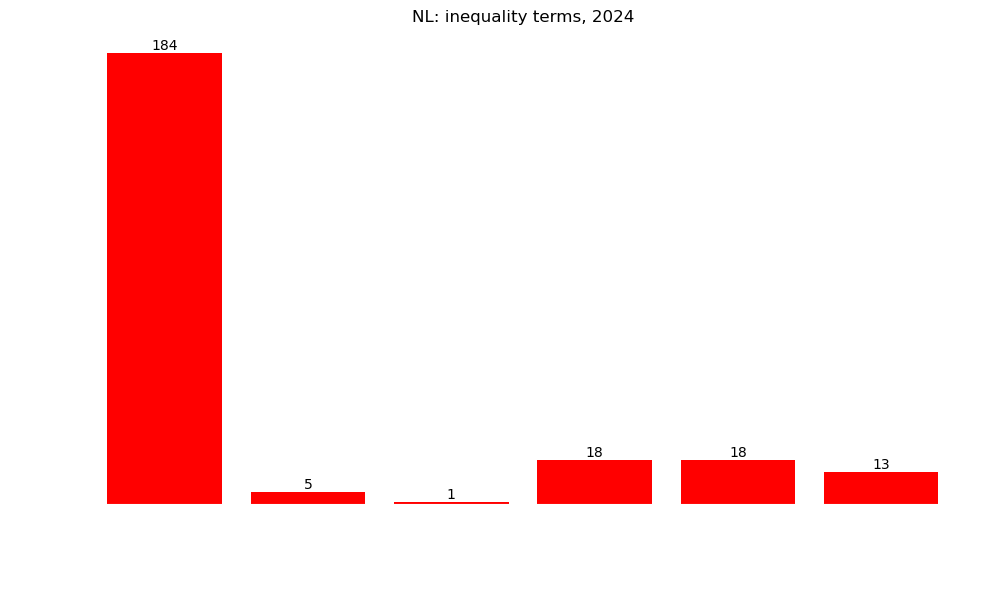

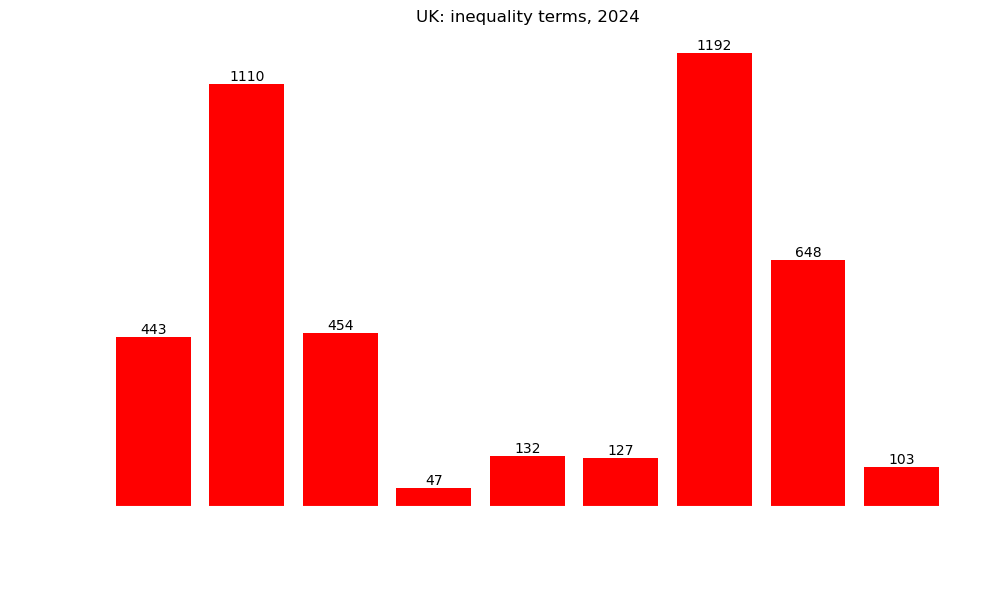

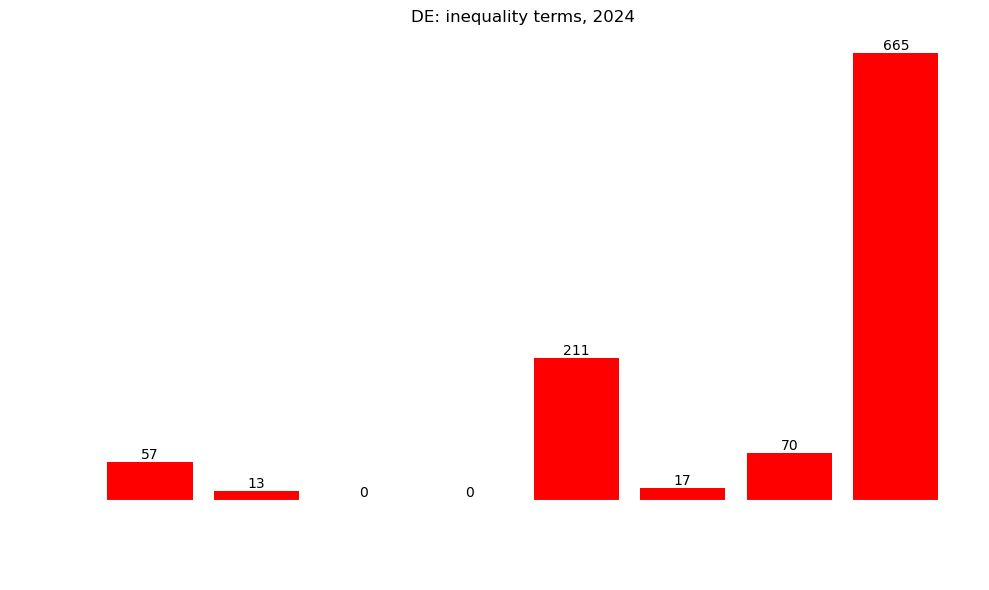

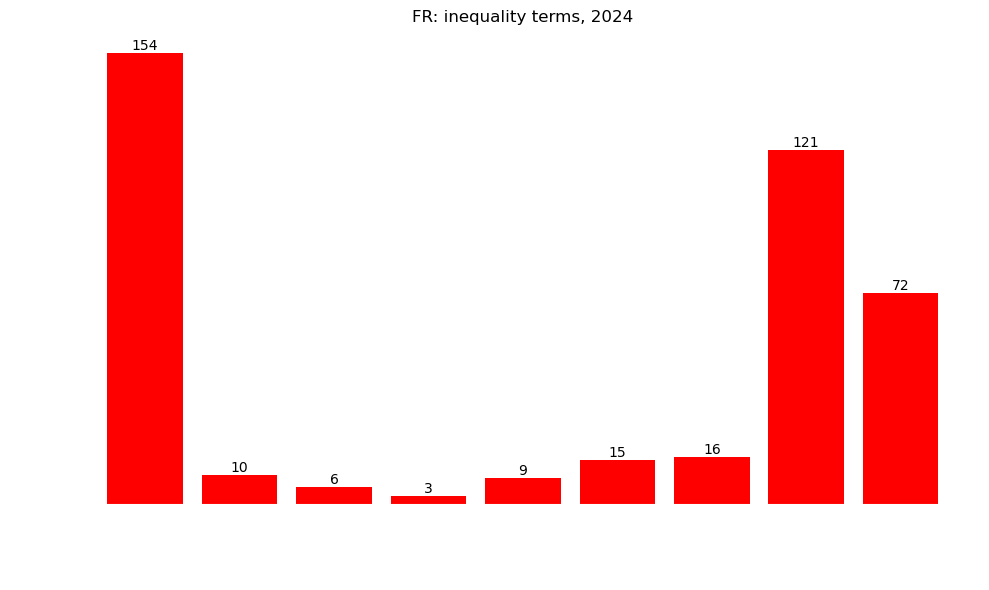

'\n    # Add horizontal lines for values in the legend\n    #for value in [25, 50, 75, 100, 125, 150, 175, 200]:\n    #    plt.axhline(y=value, color=\'grey\', linestyle=\'--\', linewidth=0.5)\n    #plt.bar(column_sums.index, column_sums.values, color=\'red\')\n\n    # Customize the plot\n    plt.ylabel("Sum of term frequencies")\n    plt.xticks(rotation=45, ha="right", fontsize=16)\n    plt.tight_layout()\n\n    ax.set_ylabel(\'Sum of term frequencies\', color=\'white\')\n    ax.set_title(\'Terms related to social inequality in 2024 corpus of Dutch websites\', color=\'white\')\n    ax.spines[\'bottom\'].set_color(\'white\')\n    ax.spines[\'top\'].set_color(\'white\')\n    ax.spines[\'left\'].set_color(\'white\')\n    ax.spines[\'right\'].set_color(\'white\')\n    ax.tick_params(axis=\'x\', colors=\'white\')\n    ax.tick_params(axis=\'y\', colors=\'white\')\n\n    plt.text(-0.8, -40, f"total websites: {len(df.domain.unique())}", fontsize=10, color=\'white\')\n    plt.savefig(f\'output

In [49]:
# Calculate the sum of values for each specified column
count_pages = False   # False: total occurrences; True: number of pages containing the term

for cc, df in zip(cc_list, dataframes):
    terms = inequality_terms[cc]
    values = (df[terms] > 0).sum() if count_pages else df[terms].sum()

    fig, ax = plt.subplots(figsize=(10, 6))
    ax.bar(terms, values[terms].values, color='red')
    ax.set_title(f'{cc}: inequality terms, 2024')
    ax.set_ylabel('Pages containing the term' if count_pages else 'Total occurrences')
    ax.tick_params(axis='x', rotation=45)
    plt.setp(ax.get_xticklabels(), ha='right')
    for i, v in enumerate(values[terms].values):
        ax.text(i, v, f'{int(v)}', ha='center', va='bottom')   # value label on top of each bar
    ax.set_ylabel('Sum of term frequencies', color='white')
    ax.spines['bottom'].set_color('white')
    ax.spines['top'].set_color('white')
    ax.spines['left'].set_color('white')
    ax.spines['right'].set_color('white')
    ax.tick_params(axis='x', colors='white')
    ax.tick_params(axis='y', colors='white')
    fig.tight_layout()
    fig.savefig(f'outputs/{cc}_2024_inequality.png', dpi=200)
    plt.show()


In [ ]:
df = df.drop(terms_list_all, axis=1)
df.head()

## Terms related to nobility according to their gender

In [ ]:
NL_nobility = [('ridder',0), ('jonkvrouw',1),
                        ('baron',0), ('barones',1),
                         ('graaf',0), ('gravin',1),
                          ('hertog',0), ('hertogin',1),
                          ('prins',0), ('prinses',1)] # 0 = male titles, 1 = female title
UK_nobility = [('sir',0), ('lady',1), ('knight',0),
                        ('baron',0), ('baroness',1),
                         ('duke',0), ('duchess',1),
                          ('prince',0), ('princess',1),
                           ('king',0), ('queen',1)]
DE_nobility = [ ('ritter',0), 
                         ('graf',0), ('gräfin',1),
                          ('fürst',0),('fürstin',1),
                          ('herzog',0), ('herzogin',1),
                           ('prinz',0), ('prinzessin',1),
                            ('könig', 0),('königin', 1)]
FR_nobility = [('chevalier',0), ('dame',1), ('baron',0), ('baronne',1),
                          ('duc',0), ('duchesse',1), ('marquis',0), ('marquise',1),
                           ('prince',0), ('princesse',1), ('roi',0), ('reine',1)]

## Compare TF-IDF across corpora

In [17]:
from sklearn.feature_extraction.text import TfidfVectorizer

# Initiate separate corpora and compute step by step to not overflow the RAM
corpus_NL = df_NL['text'].dropna().tolist()
corpus_UK = df_UK['text'].dropna().tolist()
corpus_DE = df_DE['text'].dropna().tolist()
corpus_FR = df_FR['text'].dropna().tolist()

In [ ]:
# Calculate tf-idf scores for NL corpus

vectorizer_NL = TfidfVectorizer()
tfidf_matrix_NL = vectorizer_NL.fit_transform(corpus_NL)
feature_names_NL = vectorizer_NL.get_feature_names_out()
# Calculate TF-IDF scores for each term in each document
tfidf_scores_NL = tfidf_matrix_NL.toarray()

In [ ]:
# Calculate tf-idf scores for UK corpus

vectorizer_UK = TfidfVectorizer()
tfidf_matrix_UK = vectorizer_UK.fit_transform(corpus_UK)
feature_names_UK = vectorizer_UK.get_feature_names_out()
# Calculate TF-IDF scores for each term in each document
tfidf_scores_UK = tfidf_matrix_UK.toarray()

In [ ]:
# Calculate tf-idf scores for DE corpus

vectorizer_DE = TfidfVectorizer()
tfidf_matrix_DE = vectorizer_DE.fit_transform(corpus_DE)
feature_names_DE = vectorizer_DE.get_feature_names_out()
# Calculate TF-IDF scores for each term in each document
tfidf_scores_DE = tfidf_matrix_DE.toarray()

In [ ]:
# Calculate tf-idf scores for FR corpus

vectorizer_FR = TfidfVectorizer()
tfidf_matrix_FR = vectorizer_FR.fit_transform(corpus_FR)
feature_names_FR = vectorizer_FR.get_feature_names_out()
# Calculate TF-IDF scores for each term in each document
tfidf_scores_FR = tfidf_matrix_FR.toarray()

In [22]:
feature_names_UK

array(['00', '000', '0000', ..., '𝐬𝐡𝐨𝐰', '𝐭𝐨', '𝟏𝟗𝐭𝐡'], dtype=object)